# What is Business EDA
- Business EDA is the process of analyzing data to answer business questions, identify patterns and support decision-making.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df=pd.read_csv("/Users/nidagallusandeep/Downloads/day43_eda_business_questions.csv")

In [3]:
df.shape

(80, 12)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 80 entries, 0 to 79
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Order_ID          80 non-null     object 
 1   Order_Date        80 non-null     object 
 2   City              79 non-null     object 
 3   Category          80 non-null     object 
 4   Product           80 non-null     object 
 5   Payment_Method    80 non-null     object 
 6   Order_Status      80 non-null     object 
 7   Quantity          80 non-null     int64  
 8   Unit_Price_INR    80 non-null     int64  
 9   Discount_Percent  80 non-null     int64  
 10  Revenue_INR       79 non-null     float64
 11  Customer_Rating   79 non-null     float64
dtypes: float64(2), int64(3), object(7)
memory usage: 7.6+ KB


In [5]:
df.duplicated().sum()

np.int64(0)

In [6]:
df.isnull().sum()

Order_ID            0
Order_Date          0
City                1
Category            0
Product             0
Payment_Method      0
Order_Status        0
Quantity            0
Unit_Price_INR      0
Discount_Percent    0
Revenue_INR         1
Customer_Rating     1
dtype: int64

In [9]:
df["City"]=df["City"].fillna(df["City"].mode()[0])
df["Revenue_INR"]=df["Revenue_INR"].fillna(df["Revenue_INR"].mean())
df["Customer_Rating"]=df["Customer_Rating"].fillna(df["Customer_Rating"].mean())

In [10]:
df.isnull().sum()

Order_ID            0
Order_Date          0
City                0
Category            0
Product             0
Payment_Method      0
Order_Status        0
Quantity            0
Unit_Price_INR      0
Discount_Percent    0
Revenue_INR         0
Customer_Rating     0
dtype: int64

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 80 entries, 0 to 79
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Order_ID          80 non-null     object 
 1   Order_Date        80 non-null     object 
 2   City              80 non-null     object 
 3   Category          80 non-null     object 
 4   Product           80 non-null     object 
 5   Payment_Method    80 non-null     object 
 6   Order_Status      80 non-null     object 
 7   Quantity          80 non-null     int64  
 8   Unit_Price_INR    80 non-null     int64  
 9   Discount_Percent  80 non-null     int64  
 10  Revenue_INR       80 non-null     float64
 11  Customer_Rating   80 non-null     float64
dtypes: float64(2), int64(3), object(7)
memory usage: 7.6+ KB


In [13]:
df.columns

Index(['Order_ID', 'Order_Date', 'City', 'Category', 'Product',
       'Payment_Method', 'Order_Status', 'Quantity', 'Unit_Price_INR',
       'Discount_Percent', 'Revenue_INR', 'Customer_Rating'],
      dtype='object')

In [14]:
df["Order_Date"] = pd.to_datetime(df["Order_Date"])

In [15]:
# What is the total revenue
df["Revenue_INR"].sum()

np.float64(2463183.7974683545)

In [16]:
# What is the average revenue?
df["Revenue_INR"].mean()

np.float64(30789.79746835443)

In [19]:
# Which city generates the highest revenue?
highest=df.groupby("City")["Revenue_INR"].sum()
highest.sort_values(ascending=False)

City
Chennai       690169.250000
Hyderabad     648596.697468
Bengaluru     523988.700000
Kurnool       342304.900000
Vijayawada    258124.250000
Name: Revenue_INR, dtype: float64

In [20]:
# Which category generates the highest revenue?
category_revenue = df.groupby("Category")["Revenue_INR"].sum()
category_revenue.sort_values(ascending=False)

Category
Furniture      702689.700000
Clothing       658256.600000
Grocery        416483.947468
Books          389743.550000
Electronics    296010.000000
Name: Revenue_INR, dtype: float64

In [21]:
# Which product sells the most?
df.groupby("Product")["Quantity"].sum().sort_values(ascending=False)

Product
Chair     58
Rice      54
Shirt     50
Book      49
Laptop    48
Phone     27
Name: Quantity, dtype: int64

In [22]:
# Which city has the most orders?
df["City"].value_counts()

City
Chennai       21
Hyderabad     20
Bengaluru     18
Kurnool       12
Vijayawada     9
Name: count, dtype: int64

In [23]:
# What is the average customer rating by category?
df.groupby("Category")["Customer_Rating"].mean()

Category
Books          4.000000
Clothing       3.886957
Electronics    3.383333
Furniture      3.352405
Grocery        3.566667
Name: Customer_Rating, dtype: float64

In [24]:
# Which payment method is most popular?
df["Payment_Method"].value_counts()

Payment_Method
Credit Card    28
Debit Card     25
Cash           16
UPI            11
Name: count, dtype: int64

In [25]:
# Which city has the highest average order value?
df.groupby("City")["Revenue_INR"].mean().sort_values(ascending=False)

City
Chennai       32865.202381
Hyderabad     32429.834873
Bengaluru     29110.483333
Vijayawada    28680.472222
Kurnool       28525.408333
Name: Revenue_INR, dtype: float64

In [26]:
# What percentage of orders use each payment method?
df["Payment_Method"].value_counts(normalize=True) * 100

Payment_Method
Credit Card    35.00
Debit Card     31.25
Cash           20.00
UPI            13.75
Name: proportion, dtype: float64

In [27]:
# What is the order status distribution?
df["Order_Status"].value_counts()

Order_Status
Delivered    53
Pending      10
Returned      9
Cancelled     8
Name: count, dtype: int64

In [28]:
# What percentage of orders are cancelled?
cancelled_percentage = (df["Order_Status"].eq("Cancelled").mean() * 100)
print(cancelled_percentage)

10.0


In [29]:
# Which city has the most cancelled orders?
cancelled = df[df["Order_Status"] == "Cancelled"]
cancelled["City"].value_counts()

City
Hyderabad    4
Chennai      3
Kurnool      1
Name: count, dtype: int64

In [30]:
# Which category has the most returned orders?
returned = df[df["Order_Status"] == "Returned"]
returned["Category"].value_counts()

Category
Clothing       5
Electronics    2
Books          1
Furniture      1
Name: count, dtype: int64

In [31]:
# What is the monthly revenue?
df["Month"] = df["Order_Date"].dt.to_period("M")
monthly_revenue = df.groupby("Month")["Revenue_INR"].sum()
monthly_revenue

Month
2026-01    887320.097468
2026-02    751591.300000
2026-03    824272.400000
Freq: M, Name: Revenue_INR, dtype: float64

In [32]:
# Does discount affect revenue?
df.groupby("Discount_Percent")["Revenue_INR"].mean()

Discount_Percent
0     38682.778814
5     31386.155882
10    28843.740000
15    28631.709091
20    25149.493333
25    26752.218750
Name: Revenue_INR, dtype: float64

In [33]:
#What is the relationship between quantity and revenue?
df["Quantity"].corr(df["Revenue_INR"])

np.float64(0.5971136998042239)

In [34]:
# Which city and category combination generates the highest revenue?
city_category = df.groupby(["City", "Category"])["Revenue_INR"].sum()
city_category.sort_values(ascending=False)

City        Category   
Chennai     Furniture      294582.000000
Bengaluru   Clothing       251898.050000
Hyderabad   Grocery        197961.647468
Kurnool     Clothing       183982.500000
Chennai     Clothing       152978.350000
            Books          147405.000000
Hyderabad   Books          143478.000000
Vijayawada  Furniture      140295.300000
Hyderabad   Electronics    131660.750000
            Furniture      106098.600000
Bengaluru   Furniture      101789.700000
            Grocery         95820.000000
Kurnool     Books           92058.000000
Vijayawada  Grocery         76735.000000
Hyderabad   Clothing        69397.700000
Bengaluru   Electronics     67678.400000
Kurnool     Furniture       59924.100000
Chennai     Electronics     55576.900000
Vijayawada  Electronics     41093.950000
Chennai     Grocery         39627.000000
Bengaluru   Books            6802.550000
Kurnool     Grocery          6340.300000
Name: Revenue_INR, dtype: float64

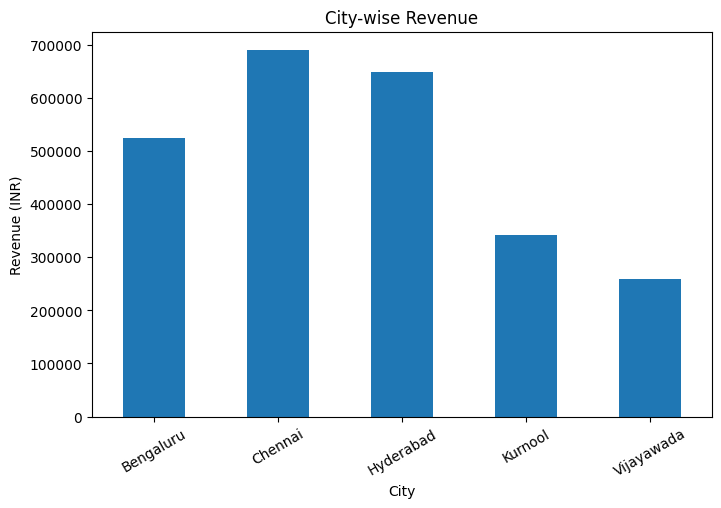

In [35]:
# Create a city-wise revenue chart
city_revenue = df.groupby("City")["Revenue_INR"].sum()
city_revenue.plot(kind="bar", figsize=(8, 5))
plt.title("City-wise Revenue")
plt.xlabel("City")
plt.ylabel("Revenue (INR)")
plt.xticks(rotation=30)
plt.show()

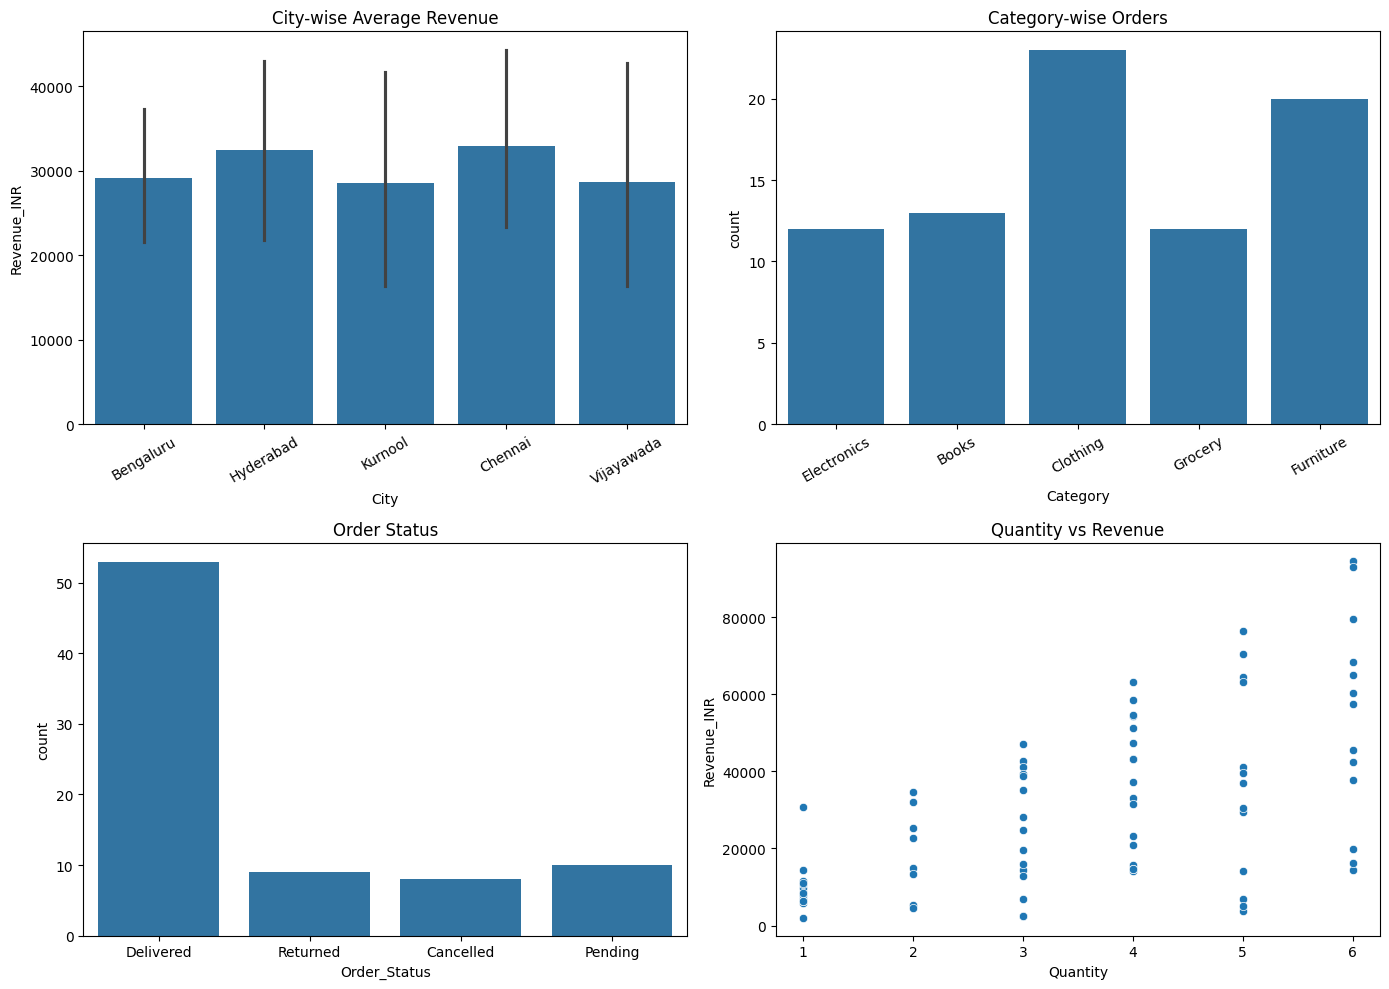

In [38]:
# Create a business dashboard using four charts
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
sns.barplot(data=df, x="City", y="Revenue_INR",ax=axes[0, 0])
axes[0, 0].set_title("City-wise Average Revenue")
axes[0, 0].tick_params(axis="x", rotation=30)
sns.countplot(data=df, x="Category",ax=axes[0, 1])
axes[0, 1].set_title("Category-wise Orders")
axes[0, 1].tick_params(axis="x", rotation=30)

sns.countplot(
    data=df, x="Order_Status",
    ax=axes[1, 0])
axes[1, 0].set_title("Order Status")

sns.scatterplot(
    data=df, x="Quantity", y="Revenue_INR",
    ax=axes[1, 1])
axes[1, 1].set_title("Quantity vs Revenue")
plt.tight_layout()
plt.show()